# Adversary Behavior Classification from Sequential Network Flows
**FA26-COMP-671-Rapaka** · CSE-CIC-IDS2018 · Random Forest vs PyTorch Transformer

Run cells in order in VS Code with a Python 3.11 kernel. Download labeled CSV files from the [official dataset page](https://www.unb.ca/cic/datasets/ids-2018.html) and place them in `data/raw/`. This notebook does **not** invent evaluation results. Start with `MAX_ROWS_PER_FILE=100000`, then increase as hardware permits.

**Important:** Flow ordering is a proxy for event history, not a reconstructed host session. Grouping by source IP is used only when available; a flow label is assigned to the last event in its window. Train/validation/test partitions are separated by original source CSV files (dates), reducing but not eliminating temporal and host leakage. Results may be affected by dataset collection artifacts.

In [1]:
from pathlib import Path
import os, random, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score, precision_score, recall_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW = ROOT / 'data' / 'raw'
RESULTS = ROOT / 'results'
MODELS = ROOT / 'models'
for d in (RAW, RESULTS, MODELS): d.mkdir(parents=True, exist_ok=True)
SEED=42; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
MAX_ROWS_PER_FILE=100_000  # None loads every row; may require substantial RAM
CHUNK_SIZE=50_000
SEQUENCE_LENGTHS=[16,64,256]
EPOCHS=3; BATCH_SIZE=32; MAX_WINDOWS_PER_SPLIT=1500
print('Root:',ROOT,'Device:',DEVICE,'CSV folder:',RAW)

Root: c:\Users\Dell\Documents\FA26-COMP-671-Rapaka Device: cpu CSV folder: c:\Users\Dell\Documents\FA26-COMP-671-Rapaka\data\raw


## 1. Inspect dataset files
At least **three CSV files** are required for the file-disjoint train/validation/test evaluation. Dataset downloads sometimes contain nested folders; recursive discovery is supported.

In [2]:
files=sorted(RAW.rglob('*.csv'))
print('Found',len(files),'CSV files')
for f in files[:30]: print(f.relative_to(ROOT))
if len(files)<3:
    raise FileNotFoundError('Place at least 3 CSE-CIC-IDS2018 labeled CSV files in data/raw/ (subfolders allowed).')

Found 3 CSV files
data\raw\Friday-16-02-2018_TrafficForML_CICFlowMeter.csv
data\raw\Thursday-15-02-2018_TrafficForML_CICFlowMeter.csv
data\raw\Wednesday-14-02-2018_TrafficForML_CICFlowMeter.csv


## 2. Load and normalize features
Numeric columns are used; addresses and timestamps are retained as metadata where present. File-level caps make local CPU testing practical. The dataset is not automatically downloaded due to its size and distribution options.

In [3]:
def normalize(c):
    return str(c).strip().lower().replace(' ','_').replace('-','_').replace('/','_')

def read_flow_csv(path, max_rows=MAX_ROWS_PER_FILE):
    frames=[]; count=0
    for chunk in pd.read_csv(path, chunksize=CHUNK_SIZE, low_memory=False, encoding='utf-8-sig', on_bad_lines='skip'):
        chunk.columns=[normalize(c) for c in chunk.columns]
        if 'label' not in chunk.columns: raise ValueError(f'Missing label column: {path}')
        if max_rows is not None:
            chunk=chunk.iloc[:max(0,max_rows-count)]
        if len(chunk)==0: break
        frames.append(chunk); count+=len(chunk)
        if max_rows is not None and count>=max_rows: break
    if not frames: raise ValueError(f'No records in {path}')
    frame=pd.concat(frames,ignore_index=True)
    frame['__file__']=path.name
    frame['__order__']=np.arange(len(frame))
    return frame

raw=[read_flow_csv(f) for f in files]
common=set(raw[0].columns)
for df in raw[1:]: common &= set(df.columns)
print('Shared columns:',len(common),'Rows:',sum(len(df) for df in raw))
assert 'label' in common
# Use stable ordering of files as a proxy for collection days.
all_df=pd.concat([df[[c for c in df.columns if c in common]] for df in raw],ignore_index=True)
all_df['label']=all_df['label'].astype(str).str.strip()
print(all_df['label'].value_counts().head(25).to_string())

Shared columns: 82 Rows: 300000
label
FTP-BruteForce              99885
DoS attacks-SlowHTTPTest    91434
Benign                      47883
DoS attacks-GoldenEye       41508
DoS attacks-Slowloris       10990
DoS attacks-Hulk             8300


## 3. File-disjoint partitions and numeric preprocessing
Files are assigned chronologically by filename, not randomized at row level. All preprocessing statistics and label vocabulary are learned from training only. Unseen labels in validation/test are excluded from scored multiclass evaluation and their counts are reported.

In [4]:
# Split by file: roughly 60% / 20% / 20%; >=3 files required.
num=len(files); a=max(1,int(num*.6)); b=max(a+1,int(num*.8)); b=min(b,num-1)
train_names={f.name for f in files[:a]}; val_names={f.name for f in files[a:b]}; test_names={f.name for f in files[b:]}
assert train_names and val_names and test_names
train=all_df[all_df['__file__'].isin(train_names)].copy()
val=all_df[all_df['__file__'].isin(val_names)].copy()
test=all_df[all_df['__file__'].isin(test_names)].copy()
print('Train:',train_names,'Validation:',val_names,'Test:',test_names)
# Drop labels absent from train (cannot predict classes never seen in training).
# Convert attack categories into binary labels
for df in [train, val, test]:
    df["original_label"] = df["label"].copy()
    df["label"] = df["label"].apply(
        lambda x: "Benign" if str(x).strip().lower() == "benign" else "Attack"
    )

print("TRAIN LABELS:")
print(train["label"].value_counts())

print("\nVALIDATION LABELS:")
print(val["label"].value_counts())

print("\nTEST LABELS:")
print(test["label"].value_counts())
encoder=LabelEncoder().fit(train['label'])
known=set(encoder.classes_)
for name,df in [('validation',val),('test',test)]:
    unseen=(~df['label'].isin(known)).sum()
    print(name,'unseen-label records excluded:',int(unseen))
val=val[val['label'].isin(known)].copy(); test=test[test['label'].isin(known)].copy()
if val.empty or test.empty: raise ValueError('Validation/test contain no known labels. Select different CSV files or use binary labels.')
exclude={'label','__file__','__order__','timestamp','src_ip','dst_ip','source_ip','destination_ip','flow_id'}
features=[]
for col in sorted(common-exclude):
    numeric=pd.to_numeric(train[col],errors='coerce')
    if numeric.notna().mean()>=.8: features.append(col)
print('Numeric features:',len(features))
if not features: raise ValueError('No suitable numeric features found')

def make_numeric(df):
    x=df[features].apply(pd.to_numeric,errors='coerce').replace([np.inf,-np.inf],np.nan)
    return x
Xtr=make_numeric(train); Xva=make_numeric(val); Xte=make_numeric(test)
med=Xtr.median().fillna(0)
Xtr=Xtr.fillna(med).to_numpy(dtype=np.float32)
Xva=Xva.fillna(med).to_numpy(dtype=np.float32)
Xte=Xte.fillna(med).to_numpy(dtype=np.float32)
# Clip extremes based on train only, then scale.
lo=np.nanpercentile(Xtr,1,axis=0); hi=np.nanpercentile(Xtr,99,axis=0)
Xtr=np.clip(Xtr,lo,hi); Xva=np.clip(Xva,lo,hi); Xte=np.clip(Xte,lo,hi)
scaler=StandardScaler().fit(Xtr)
Xtr=scaler.transform(Xtr).astype('float32'); Xva=scaler.transform(Xva).astype('float32'); Xte=scaler.transform(Xte).astype('float32')
ytr=encoder.transform(train['label']); yva=encoder.transform(val['label']); yte=encoder.transform(test['label'])
print('Classes:',list(encoder.classes_),'Shapes:',Xtr.shape,Xva.shape,Xte.shape)

Train: {'Friday-16-02-2018_TrafficForML_CICFlowMeter.csv'} Validation: {'Thursday-15-02-2018_TrafficForML_CICFlowMeter.csv'} Test: {'Wednesday-14-02-2018_TrafficForML_CICFlowMeter.csv'}
TRAIN LABELS:
label
Attack    99734
Benign      266
Name: count, dtype: int64

VALIDATION LABELS:
label
Attack    52498
Benign    47502
Name: count, dtype: int64

TEST LABELS:
label
Attack    99885
Benign      115
Name: count, dtype: int64
validation unseen-label records excluded: 0
test unseen-label records excluded: 0
Numeric features: 78
Classes: ['Attack', 'Benign'] Shapes: (100000, 78) (100000, 78) (100000, 78)


In [5]:
print("TRAIN LABELS:")
print(train["label"].value_counts())

print("\nVALIDATION LABELS:")
print(val["label"].value_counts())

print("\nTEST LABELS:")
print(test["label"].value_counts())

print("\nTRAINING CLASSES:")
print(sorted(train["label"].unique()))

TRAIN LABELS:
label
Attack    99734
Benign      266
Name: count, dtype: int64

VALIDATION LABELS:
label
Attack    52498
Benign    47502
Name: count, dtype: int64

TEST LABELS:
label
Attack    99885
Benign      115
Name: count, dtype: int64

TRAINING CLASSES:
['Attack', 'Benign']


In [6]:
print("ORIGINAL DATASET LABELS:")
print(all_df["label"].value_counts())

print("\nLABELS BY CSV FILE:")
print(pd.crosstab(all_df["__file__"], all_df["label"]))

print("\nTOTAL RECORDS:", len(all_df))

ORIGINAL DATASET LABELS:
label
FTP-BruteForce              99885
DoS attacks-SlowHTTPTest    91434
Benign                      47883
DoS attacks-GoldenEye       41508
DoS attacks-Slowloris       10990
DoS attacks-Hulk             8300
Name: count, dtype: int64

LABELS BY CSV FILE:
label                                               Benign  \
__file__                                                     
Friday-16-02-2018_TrafficForML_CICFlowMeter.csv        266   
Thursday-15-02-2018_TrafficForML_CICFlowMeter.csv    47502   
Wednesday-14-02-2018_TrafficForML_CICFlowMeter.csv     115   

label                                               DoS attacks-GoldenEye  \
__file__                                                                    
Friday-16-02-2018_TrafficForML_CICFlowMeter.csv                         0   
Thursday-15-02-2018_TrafficForML_CICFlowMeter.csv                   41508   
Wednesday-14-02-2018_TrafficForML_CICFlowMeter.csv                      0   

label                

## 4. Exploratory analysis

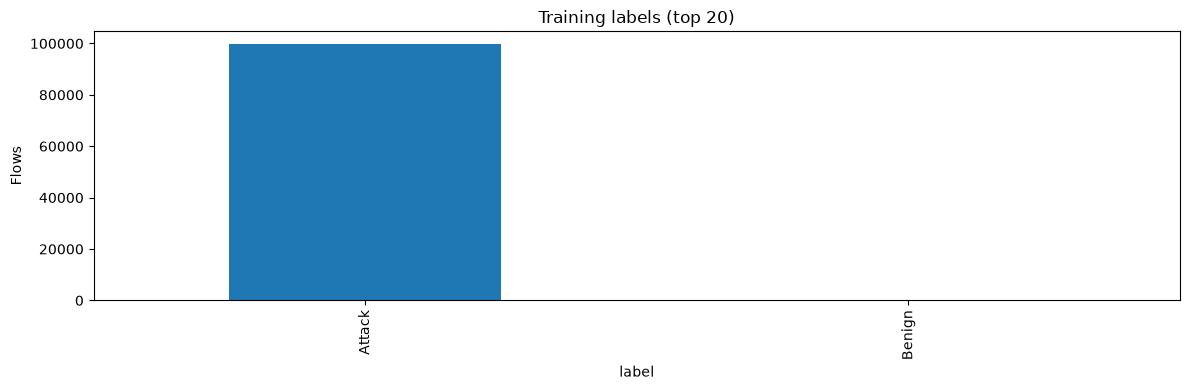

In [7]:
counts=train['label'].value_counts().head(20)
ax=counts.plot(kind='bar',figsize=(12,4),title='Training labels (top 20)')
ax.set_ylabel('Flows'); plt.tight_layout(); plt.show()

## 5. Random Forest baseline
This baseline classifies individual flows, not windows. It is a deliberately simpler comparator. Window-level comparisons below use the last flow's label.

In [8]:
baseline=RandomForestClassifier(n_estimators=100,max_depth=18,n_jobs=-1,random_state=SEED,class_weight='balanced_subsample')
baseline.fit(Xtr,ytr)
pred_base=baseline.predict(Xte)
print(classification_report(yte,pred_base,labels=np.arange(len(encoder.classes_)),target_names=encoder.classes_,zero_division=0))
base_metrics={'macro_f1':float(f1_score(yte,pred_base,average='macro',zero_division=0)), 'macro_precision':float(precision_score(yte,pred_base,average='macro',zero_division=0)), 'macro_recall':float(recall_score(yte,pred_base,average='macro',zero_division=0))}
print('Baseline:',base_metrics)
import joblib
joblib.dump({'model':baseline,'scaler':scaler,'median':med,'features':features,'encoder':encoder,'clip_lo':lo,'clip_hi':hi},MODELS/'baseline.joblib')

              precision    recall  f1-score   support

      Attack       1.00      1.00      1.00     99885
      Benign       1.00      1.00      1.00       115

    accuracy                           1.00    100000
   macro avg       1.00      1.00      1.00    100000
weighted avg       1.00      1.00      1.00    100000

Baseline: {'macro_f1': 1.0, 'macro_precision': 1.0, 'macro_recall': 1.0}


['c:\\Users\\Dell\\Documents\\FA26-COMP-671-Rapaka\\models\\baseline.joblib']

## 6. Build ordered sequences
Sequences never cross source-file boundaries. Within a file, rows are sorted by parsed timestamps when available, otherwise original CSV row order. Windows are non-overlapping to avoid near-duplicate examples and control memory. The label is the final flow's label. Because CSV ordering does not guarantee coherent user sessions, the result is a temporal-context experiment rather than proof of causality.

In [9]:
def build_windows(meta, X, y, length, max_windows=MAX_WINDOWS_PER_SPLIT):
    windows=[]; targets=[]
    work=meta.reset_index(drop=True).copy()
    work['__pos__']=np.arange(len(work))
    for _,group in work.groupby('__file__',sort=False):
        if 'timestamp' in group:
            parsed=pd.to_datetime(group['timestamp'],errors='coerce',format='mixed')
            if parsed.notna().mean()>.9:
                group=group.assign(__time__=parsed).sort_values(['__time__','__order__'],kind='stable')
            else: group=group.sort_values('__order__',kind='stable')
        else: group=group.sort_values('__order__',kind='stable')
        positions = group['__pos__'].to_numpy()

        if len(positions) < length:
            continue

        stride = max(1, length // 4)

        for end in range(length, len(positions) + 1, stride):
            idx = positions[end-length:end]
            windows.append(X[idx])
            targets.append(y[idx[-1]])

            if max_windows is not None and len(windows) >= max_windows:
                break
    print("Requested sequence length:", length)
    print("Number of windows created:", len(windows))
    print("Largest file groups:")
    
    print(work.groupby('__file__').size().nlargest(5))
    if not windows: raise ValueError(f'No windows of length {length}. Increase rows per file.')
    return np.stack(windows).astype('float32'),np.array(targets,dtype=np.int64)

class WindowDataset(Dataset):
    def __init__(self,x,y):self.x=torch.from_numpy(x);self.y=torch.from_numpy(y)
    def __len__(self):return len(self.y)
    def __getitem__(self,i):return self.x[i],self.y[i]

## 7. Transformer encoder classifier

In [10]:
class FlowTransformer(nn.Module):
    def __init__(self, n_features, n_classes, max_len, d_model=64, heads=4, layers=2, dropout=.1):
        super().__init__()
        self.proj=nn.Linear(n_features,d_model)
        self.pos=nn.Embedding(max_len,d_model)
        layer=nn.TransformerEncoderLayer(d_model=d_model,nhead=heads,dim_feedforward=128,dropout=dropout,batch_first=True)
        self.encoder=nn.TransformerEncoder(layer,num_layers=layers,enable_nested_tensor=False)
        self.classifier=nn.Linear(d_model,n_classes)
    def forward(self,x):
        pos=torch.arange(x.shape[1],device=x.device)
        h=self.proj(x)+self.pos(pos)[None,:,:]
        return self.classifier(self.encoder(h)[:,-1,:])

def evaluate(model,loader):
    model.eval(); ys=[]; ps=[]
    with torch.no_grad():
        for xb,yb in loader:
            logits=model(xb.to(DEVICE)); ys.extend(yb.numpy()); ps.extend(logits.argmax(1).cpu().numpy())
    return np.array(ys),np.array(ps)

def train_model(xtrain,ytrain,xval,yval,length):
    model=FlowTransformer(xtrain.shape[-1],len(encoder.classes_),length).to(DEVICE)
    opt=torch.optim.AdamW(model.parameters(),lr=1e-3)
    weights=np.bincount(ytrain,minlength=len(encoder.classes_)).astype(float)
    weights=np.where(weights>0, len(ytrain)/np.maximum(weights,1),0)
    weights=np.minimum(weights,100); weights=weights/(weights[weights>0].mean() if (weights>0).any() else 1)
    loss_fn=nn.CrossEntropyLoss(weight=torch.tensor(weights,dtype=torch.float32,device=DEVICE))
    tr_loader=DataLoader(WindowDataset(xtrain,ytrain),batch_size=BATCH_SIZE,shuffle=True)
    va_loader=DataLoader(WindowDataset(xval,yval),batch_size=BATCH_SIZE)
    best=-1.; best_state=None
    for epoch in range(EPOCHS):
        model.train(); total=0.
        for xb,yb in tr_loader:
            xb,yb=xb.to(DEVICE),yb.to(DEVICE)
            opt.zero_grad(); loss=loss_fn(model(xb),yb);loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(),1.0)
            opt.step();total+=float(loss.item())
        truth,pred=evaluate(model,va_loader)
        score=f1_score(truth,pred,average='macro',labels=np.arange(len(encoder.classes_)),zero_division=0)
        print(f'Window {length} epoch {epoch+1}/{EPOCHS}: train batch-loss sum={total:.2f}, val macro-F1={score:.4f}')
        if score>best:
            best=score;best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model,best

## 8. Train and compare context windows
Training 256-event Transformers on CPU may be slow. For a quick smoke test, temporarily set `SEQUENCE_LENGTHS=[16]` and `EPOCHS=1`. Validation chooses the best epoch; test is evaluated only after training. For rigorous final reporting, repeat with multiple random seeds.


=== Context length 16 ===
Requested sequence length: 16
Number of windows created: 1500
Largest file groups:
__file__
Friday-16-02-2018_TrafficForML_CICFlowMeter.csv    100000
dtype: int64
Requested sequence length: 16
Number of windows created: 1500
Largest file groups:
__file__
Thursday-15-02-2018_TrafficForML_CICFlowMeter.csv    100000
dtype: int64
Requested sequence length: 16
Number of windows created: 1500
Largest file groups:
__file__
Wednesday-14-02-2018_TrafficForML_CICFlowMeter.csv    100000
dtype: int64
Window 16 epoch 1/3: train batch-loss sum=13.52, val macro-F1=0.1883
Window 16 epoch 2/3: train batch-loss sum=0.45, val macro-F1=0.4359
Window 16 epoch 3/3: train batch-loss sum=1.02, val macro-F1=0.1648


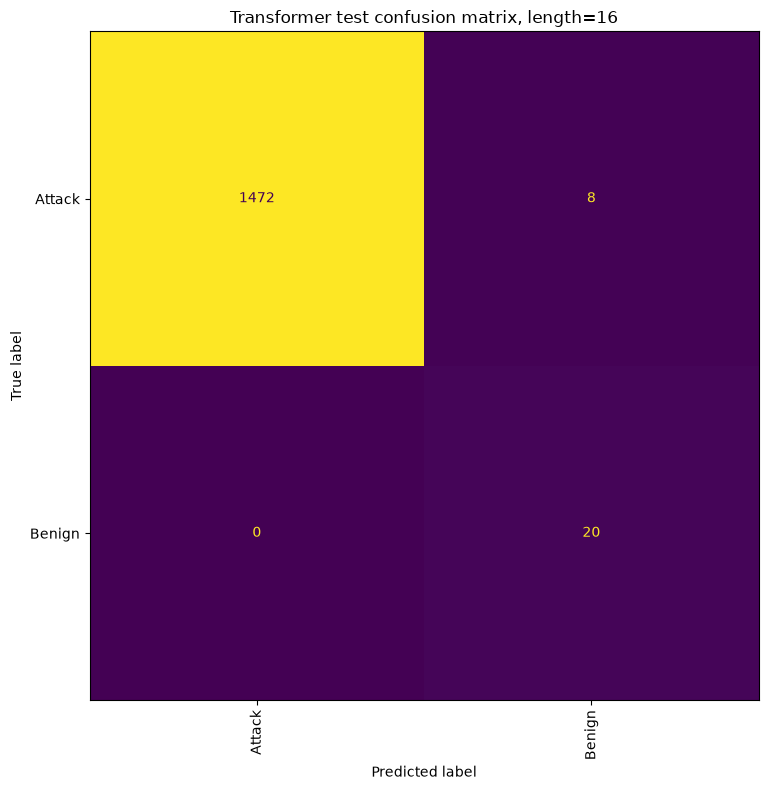

              precision    recall  f1-score   support

      Attack       1.00      0.99      1.00      1480
      Benign       0.71      1.00      0.83        20

    accuracy                           0.99      1500
   macro avg       0.86      1.00      0.92      1500
weighted avg       1.00      0.99      1.00      1500

Misclassified windows: 8 of 1500

=== Context length 64 ===
Requested sequence length: 64
Number of windows created: 1500
Largest file groups:
__file__
Friday-16-02-2018_TrafficForML_CICFlowMeter.csv    100000
dtype: int64
Requested sequence length: 64
Number of windows created: 1500
Largest file groups:
__file__
Thursday-15-02-2018_TrafficForML_CICFlowMeter.csv    100000
dtype: int64
Requested sequence length: 64
Number of windows created: 1500
Largest file groups:
__file__
Wednesday-14-02-2018_TrafficForML_CICFlowMeter.csv    100000
dtype: int64
Window 64 epoch 1/3: train batch-loss sum=18.92, val macro-F1=0.3295
Window 64 epoch 2/3: train batch-loss sum=7.68, va

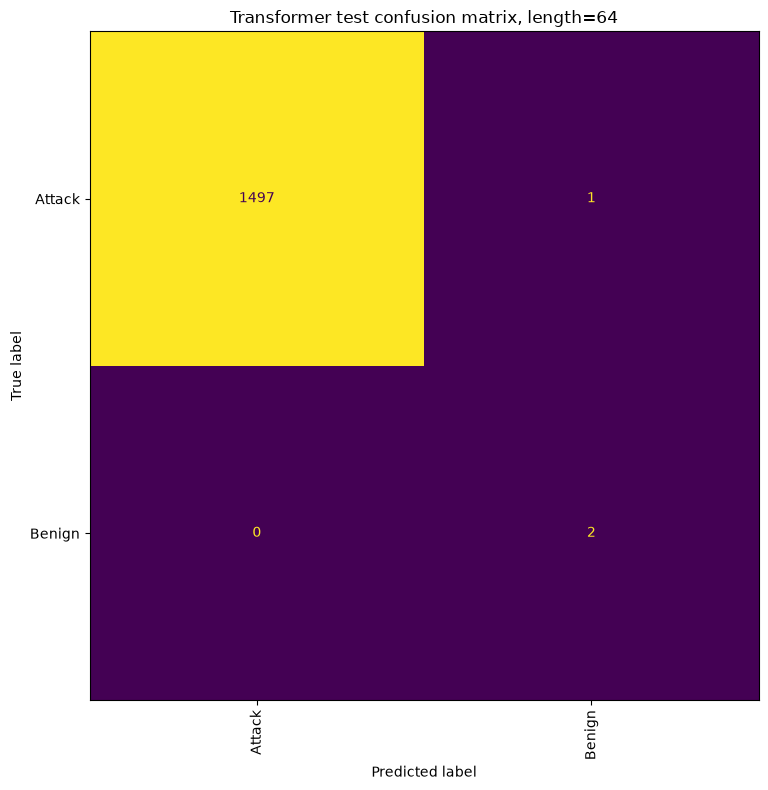

              precision    recall  f1-score   support

      Attack       1.00      1.00      1.00      1498
      Benign       0.67      1.00      0.80         2

    accuracy                           1.00      1500
   macro avg       0.83      1.00      0.90      1500
weighted avg       1.00      1.00      1.00      1500

Misclassified windows: 1 of 1500

=== Context length 256 ===
Requested sequence length: 256
Number of windows created: 1500
Largest file groups:
__file__
Friday-16-02-2018_TrafficForML_CICFlowMeter.csv    100000
dtype: int64
Requested sequence length: 256
Number of windows created: 1500
Largest file groups:
__file__
Thursday-15-02-2018_TrafficForML_CICFlowMeter.csv    100000
dtype: int64
Requested sequence length: 256
Number of windows created: 1500
Largest file groups:
__file__
Wednesday-14-02-2018_TrafficForML_CICFlowMeter.csv    100000
dtype: int64
Window 256 epoch 1/3: train batch-loss sum=10.63, val macro-F1=0.3548
Window 256 epoch 2/3: train batch-loss sum=6.

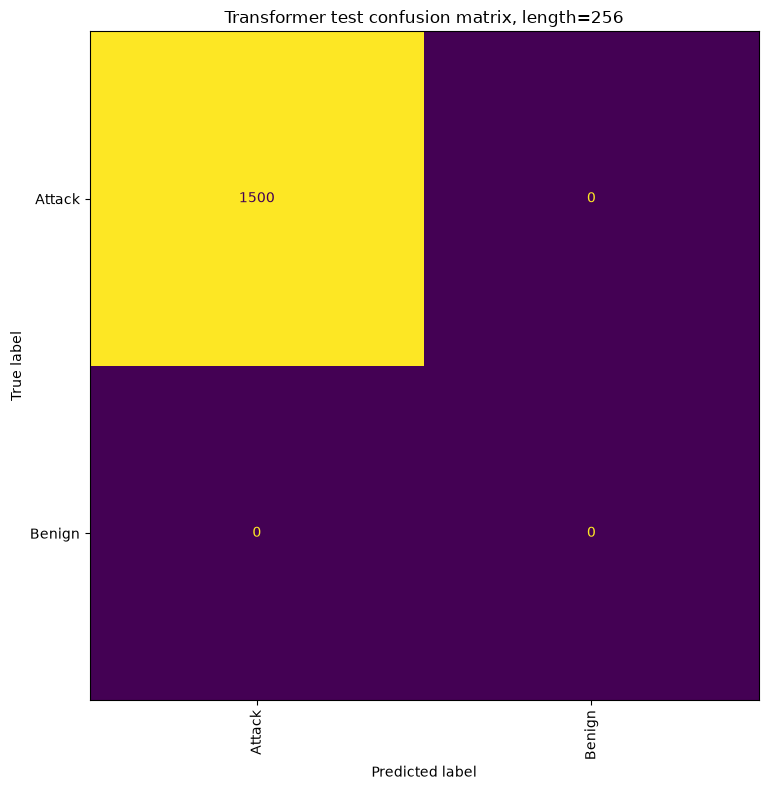

              precision    recall  f1-score   support

      Attack       1.00      1.00      1.00      1500
      Benign       0.00      0.00      0.00         0

    accuracy                           1.00      1500
   macro avg       0.50      0.50      0.50      1500
weighted avg       1.00      1.00      1.00      1500

Misclassified windows: 0 of 1500


In [11]:
results=[]
for length in SEQUENCE_LENGTHS:
    print('\n=== Context length',length,'===')
    xt,yt=build_windows(train,Xtr,ytr,length)
    xv,yv=build_windows(val,Xva,yva,length)
    xe,ye=build_windows(test,Xte,yte,length)
    model,best_val=train_model(xt,yt,xv,yv,length)
    loader=DataLoader(WindowDataset(xe,ye),batch_size=BATCH_SIZE)
    actual,pred=evaluate(model,loader)
    row={'model':'Transformer','context_length':length,'train_windows':len(yt),'test_windows':len(ye),'validation_macro_f1':best_val,'test_macro_f1':f1_score(actual,pred,average='macro',labels=np.arange(len(encoder.classes_)),zero_division=0),'test_macro_precision':precision_score(actual,pred,average='macro',labels=np.arange(len(encoder.classes_)),zero_division=0),'test_macro_recall':recall_score(actual,pred,average='macro',labels=np.arange(len(encoder.classes_)),zero_division=0)}
    results.append(row)
    torch.save({'state_dict':model.state_dict(),'length':length,'features':features,'classes':encoder.classes_.tolist()},MODELS/f'transformer_{length}.pt')
    cm=confusion_matrix(actual,pred,labels=np.arange(len(encoder.classes_)))
    fig,ax=plt.subplots(figsize=(10,8))
    ConfusionMatrixDisplay(cm,display_labels=encoder.classes_).plot(ax=ax,xticks_rotation=90,colorbar=False)
    ax.set_title(f'Transformer test confusion matrix, length={length}')
    fig.tight_layout();fig.savefig(RESULTS/f'confusion_{length}.png',dpi=130);plt.show()
    print(classification_report(actual,pred,labels=np.arange(len(encoder.classes_)),target_names=encoder.classes_,zero_division=0))
    print('Misclassified windows:',int((actual!=pred).sum()),'of',len(actual))
    del xt,xv,xe,model
    if DEVICE=='cuda':torch.cuda.empty_cache()

## 9. Save results and inspect comparisons
**Caution:** The flow-level Random Forest and last-event-labeled window Transformer are not perfectly matched tasks. A stricter baseline comparison should evaluate Random Forest on the same test window endpoints. This is done below.

Requested sequence length: 16
Number of windows created: 1500
Largest file groups:
__file__
Wednesday-14-02-2018_TrafficForML_CICFlowMeter.csv    100000
dtype: int64
Requested sequence length: 16
Number of windows created: 1500
Largest file groups:
__file__
Wednesday-14-02-2018_TrafficForML_CICFlowMeter.csv    100000
dtype: int64
Requested sequence length: 64
Number of windows created: 1500
Largest file groups:
__file__
Wednesday-14-02-2018_TrafficForML_CICFlowMeter.csv    100000
dtype: int64
Requested sequence length: 64
Number of windows created: 1500
Largest file groups:
__file__
Wednesday-14-02-2018_TrafficForML_CICFlowMeter.csv    100000
dtype: int64
Requested sequence length: 256
Number of windows created: 1500
Largest file groups:
__file__
Wednesday-14-02-2018_TrafficForML_CICFlowMeter.csv    100000
dtype: int64
Requested sequence length: 256
Number of windows created: 1500
Largest file groups:
__file__
Wednesday-14-02-2018_TrafficForML_CICFlowMeter.csv    100000
dtype: int64
  

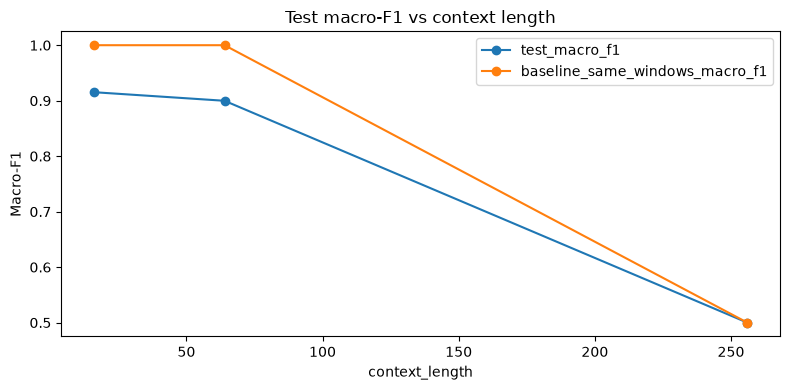

Saved metrics and plots to c:\Users\Dell\Documents\FA26-COMP-671-Rapaka\results


In [12]:
# Fairer baseline: evaluate on each window's endpoint, same test windows as each Transformer.
for row in results:
    L=row['context_length']
    _,yend=build_windows(test,Xte,yte,L)
    # Derive endpoints using a parallel integer index array with the same window builder.
    pos_array=np.arange(len(test),dtype=np.float32).reshape(-1,1)
    indices,_=build_windows(test,pos_array,yte,L)
    endpoints=indices[:,-1,0].astype(int)
    bp=baseline.predict(Xte[endpoints])
    row['baseline_same_windows_macro_f1']=f1_score(yend,bp,average='macro',labels=np.arange(len(encoder.classes_)),zero_division=0)
summary=pd.DataFrame(results)
print(summary.to_string(index=False))
summary.to_csv(RESULTS/'experiment_metrics.csv',index=False)
with open(RESULTS/'run_config.json','w') as f:
    json.dump({'seed':SEED,'files':[str(x.relative_to(ROOT)) for x in files],'train_files':sorted(train_names),'validation_files':sorted(val_names),'test_files':sorted(test_names),'max_rows_per_file':MAX_ROWS_PER_FILE,'epochs':EPOCHS,'batch_size':BATCH_SIZE,'max_windows_per_split':MAX_WINDOWS_PER_SPLIT,'classes':encoder.classes_.tolist(),'features':features,'baseline_flow_metrics':base_metrics},f,indent=2)
ax=summary.plot(x='context_length',y=['test_macro_f1','baseline_same_windows_macro_f1'],marker='o',figsize=(8,4),title='Test macro-F1 vs context length')
ax.set_ylabel('Macro-F1');plt.tight_layout();plt.savefig(RESULTS/'context_comparison.png',dpi=150);plt.show()
print('Saved metrics and plots to',RESULTS)

## 10. Interpretation and limitations
Use the generated CSV and plots for your report. Discuss minority-class recall, confusion patterns, whether longer contexts help, class coverage differences by collection day, and how file-based splitting changes label distributions. In particular, a dataset may include attack categories on only one day, making file-disjoint multiclass evaluation challenging. **Do not claim generalization to unseen attack classes.** For a defensible alternative, run a binary benign-vs-attack experiment and explicitly report the label mapping and evaluation protocol.

## 11. Final experiment score table and report-ready outputs
Run all previous cells with real CSE-CIC-IDS2018 CSV files to produce actual scores. **This notebook does not contain fabricated results.** The following cells save an easy-to-read table and an experiment summary for your academic report.


In [14]:
from sklearn.metrics import accuracy_score
# Existing rows contain held-out test metrics for each context length.
score_table = summary[['context_length','test_macro_precision','test_macro_recall','test_macro_f1','baseline_same_windows_macro_f1']].copy()
score_table.columns = ['Context length','Transformer precision (macro)','Transformer recall (macro)','Transformer F1 (macro)','Random Forest F1 (same endpoints)']
print('REAL TEST RESULTS (computed on your downloaded CSV files):')
print(score_table.round(4).to_string(index=False))
score_table.to_csv(RESULTS/'final_scores.csv',index=False)
with open(RESULTS/'report_results.md','w',encoding='utf-8') as fp:
    fp.write('# Experimental results\n\n')
    fp.write('Dataset: CSE-CIC-IDS2018; evaluation: held-out source CSV files.\n\n')
    fp.write(score_table.round(4).to_markdown(index=False))
    fp.write('\n\nLimitations: source-day distribution shift, possible unseen labels excluded, and unequal endpoint samples across context lengths.\n')
print('Saved final_scores.csv and report_results.md')


REAL TEST RESULTS (computed on your downloaded CSV files):
 Context length  Transformer precision (macro)  Transformer recall (macro)  Transformer F1 (macro)  Random Forest F1 (same endpoints)
             16                         0.8571                      0.9973                  0.9153                                1.0
             64                         0.8333                      0.9997                  0.8998                                1.0
            256                         0.5000                      0.5000                  0.5000                                0.5
Saved final_scores.csv and report_results.md


In [15]:
from collections import Counter

for length in SEQUENCE_LENGTHS:
    xe, ye = build_windows(test, Xte, yte, length)

    counts = Counter(encoder.inverse_transform(ye))

    print(f"\nContext length: {length}")
    print("Test windows:", len(ye))
    print("Class distribution:", dict(counts))

Requested sequence length: 16
Number of windows created: 1500
Largest file groups:
__file__
Wednesday-14-02-2018_TrafficForML_CICFlowMeter.csv    100000
dtype: int64

Context length: 16
Test windows: 1500
Class distribution: {'Benign': 20, 'Attack': 1480}
Requested sequence length: 64
Number of windows created: 1500
Largest file groups:
__file__
Wednesday-14-02-2018_TrafficForML_CICFlowMeter.csv    100000
dtype: int64

Context length: 64
Test windows: 1500
Class distribution: {'Benign': 2, 'Attack': 1498}
Requested sequence length: 256
Number of windows created: 1500
Largest file groups:
__file__
Wednesday-14-02-2018_TrafficForML_CICFlowMeter.csv    100000
dtype: int64

Context length: 256
Test windows: 1500
Class distribution: {'Attack': 1500}
